# Step 3: corrupted images

Runs the 15 MedMNIST-C corruptions at 5 severities over the val + test images and saves what each model outputs. Uses the same Drive folder and `GH_TOKEN` as notebooks 1 and 2.

1. Runtime > Change runtime type > T4 GPU.
2. Run the cells in order and keep the tab open.
3. If Colab disconnects, run everything again. Finished corruptions get skipped.

After any git push, reset the runtime first or this keeps running the old code.

In [ ]:
import os
import torch
from google.colab import drive, userdata

assert torch.cuda.is_available(), "no gpu, change the runtime type to T4"
print(torch.cuda.get_device_name(0))

drive.mount("/content/drive")

token = userdata.get("GH_TOKEN")
!git clone -q https://{token}@github.com/adipatel11/gr-sats-term-paper.git /content/repo || git -C /content/repo pull -q
%cd /content/repo/code
!pip install -q -r requirements.txt

# medmnist-c pins an old scikit-image that won't build here, so skip its dependencies.
# its motion blur needs imagemagick, and apt needs an update first or it 404s
!apt-get -qq update
!apt-get -qq install -y libmagickwand-dev > /dev/null
!pip install -q --no-deps medmnistc

# outputs go to drive so they survive a disconnect
os.environ["GRSATS_OUT"] = "/content/drive/MyDrive/grsats/outputs"

Tesla T4
Mounted at /content/drive
/content/repo/code
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
# unzip to the colab disk, reading from drive is really slow
ham = "../data/HAM10000/dataverse_files"
!mkdir -p {ham}
!unzip -qn /content/drive/MyDrive/grsats/HAM10000_images_part_1.zip -d {ham}/HAM10000_images_part_1
!unzip -qn /content/drive/MyDrive/grsats/HAM10000_images_part_2.zip -d {ham}/HAM10000_images_part_2
!unzip -qn /content/drive/MyDrive/grsats/finalfitz17k.zip -d ../data

# counts should match the paper and missing image files should be 0
!python check_data.py
!python -m pytest -q


ham: 9,948 images
  train: 8,164 (1,740, 21.3%)
  val: 568 (63, 11.1%)
  test: 1,216 (149, 12.3%)
  pool: 1,784 (212, 11.9%)
  pool female: 820 (80, 9.8%)
  pool male: 964 (132, 13.7%)
  pool 60+: 578 (150, 26.0%)
  pool <60: 1,206 (62, 5.1%)
  missing image files: 0

fitz: 11,098 images
  train: 7,779 (1,144, 14.7%)
  val: 1,100 (154, 14.0%)
  test: 2,219 (325, 14.6%)
  pool: 3,319 (479, 14.4%)
  pool I-II: 1,794 (287, 16.0%)
  pool III-IV: 1,163 (160, 13.8%)
  pool V-VI: 362 (32, 8.8%)
  missing image files: 0
..........                                                               [100%]
10 passed in 16.26s


In [ ]:
# refit the probes so they get saved too (cpu, a few minutes). same features and
# settings as notebook 1, so the results should come out the same as before
for ds in ["ham", "fitz"]:
    for bb in ["dinov2", "biomedclip"]:
        !python train_probes.py --dataset {ds} --backbone {bb}


seed 0: l2 = 100, dev nll = 0.317
 group    n   auc   nll
   all 1784 0.959 0.167
female  820 0.968 0.137
  male  964 0.950 0.192
   60+  578 0.915 0.317
   <60 1206 0.966 0.095

seed 1: l2 = 100, dev nll = 0.325
 group    n   auc   nll
   all 1784 0.959 0.166
female  820 0.964 0.141
  male  964 0.954 0.188
   60+  578 0.916 0.314
   <60 1206 0.968 0.095

seed 2: l2 = 100, dev nll = 0.339
 group    n   auc   nll
   all 1784 0.959 0.166
female  820 0.966 0.138
  male  964 0.952 0.190
   60+  578 0.915 0.316
   <60 1206 0.966 0.094

ham_dinov2 mean over seeds:
          auc           nll       
         mean    std   mean    std
group                             
all     0.959  0.000  0.166  0.000
female  0.966  0.002  0.139  0.002
male    0.952  0.002  0.190  0.002
60+     0.915  0.001  0.316  0.001
<60     0.967  0.001  0.095  0.001

seed 0: l2 = 0.01, dev nll = 0.309
 group    n   auc   nll
   all 1784 0.949 0.175
female  820 0.947 0.161
  male  964 0.950 0.187
   60+  578 0.915 0.32

loading images: 100% 1/1 [00:01<00:00,  1.24s/it]
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth
100% 330M/330M [00:01<00:00, 228MB/s]
open_clip_config.json: 100% 707/707 [00:00<00:00, 4.39MB/s]

open_clip_pytorch_model.bin: d

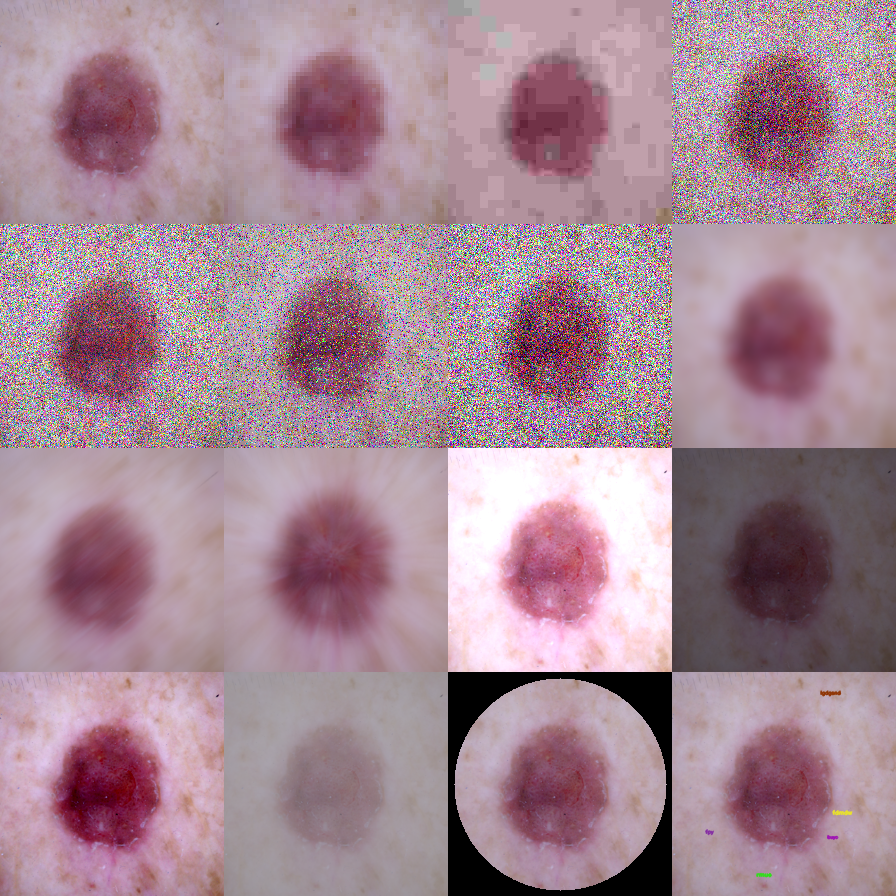

In [ ]:
# quick test on 64 images: clean check, time per corruption, and a picture to look at
from IPython.display import Image
!python corrupt_extract.py --dataset ham --models frozen --test
Image(os.environ["GRSATS_OUT"] + "/corruption_preview.png")

In [ ]:
# the pilot: ham, frozen backbones (the probes read these features)
!python corrupt_extract.py --dataset ham --models frozen

loading images: 100% 28/28 [00:14<00:00,  1.91it/s]
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
dinov2_frozen_X: max diff from saved clean outputs = 0.0013
biomedclip_frozen_X: max diff from saved clean outputs = 0.0007
pixelate severity 1: 100% 28/28 [00:10<00:00,  2.73it/s]
pixelate severity 2: 100% 28/28 [00:10<00:00,  2.69it/s]
pixelate severity 3: 100% 28/28 [00:10<00:00,  2.60it/s]
pixelate severity 4: 100

In [ ]:
# fit and compare the calibrators on the pilot outputs (cpu, about a minute)
!python calibrate.py --dataset ham --models frozen


dinov2 lp seed 0
  ts_wg - ts_corr: [-0.0371  0.0072]
  grsats - sats_avg: [-0.0222  0.0064]
  grsats theta: [ 0.8275 -0.1635]
  score female: [-0.063  1.511]
  score male: [0.0536 1.5286]
  score 60+: [0.4681 1.725 ]
  score <60: [-0.2243  1.4225]

dinov2 lp seed 1
  ts_wg - ts_corr: [-0.0367  0.0071]
  grsats - sats_avg: [-0.0227  0.0065]
  grsats theta: [ 0.8762 -0.1735]
  score female: [-0.063  1.511]
  score male: [0.0536 1.5286]
  score 60+: [0.4681 1.725 ]
  score <60: [-0.2243  1.4225]

dinov2 lp seed 2
  ts_wg - ts_corr: [-0.0408  0.0078]
  grsats - sats_avg: [-0.0254  0.0069]
  grsats theta: [ 0.8438 -0.1652]
  score female: [-0.063  1.511]
  score male: [0.0536 1.5286]
  score 60+: [0.4681 1.725 ]
  score <60: [-0.2243  1.4225]

biomedclip lp seed 0
  ts_wg - ts_corr: [-0.0349  0.0062]
  grsats - sats_avg: [-0.0215  0.0054]
  grsats theta: [ 0.7969 -0.0931]
  score female: [-0.0841  2.6874]
  score male: [0.0716 2.7424]
  score 60+: [0.1977 2.7984]
  score <60: [-0.0947  2.

## After the pilot

Only run these once the pilot says GR-SATS is worth it. They take longer.

In [ ]:
!python corrupt_extract.py --dataset ham --models lora
!python corrupt_extract.py --dataset fitz --models frozen
!python corrupt_extract.py --dataset fitz --models lora

loading images: 100% 28/28 [00:15<00:00,  1.75it/s]
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth
100% 330M/330M [00:01<00:00, 181MB/s]
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
Using cache foun

In [ ]:
!git -C /content/repo pull -q
for ds in ["ham", "fitz"]:
    for m in ["frozen", "lora"]:
        !python calibrate.py --dataset {ds} --models {m}


dinov2 lp seed 0
  ts_wg - ts_corr: [-0.0371  0.007 ]
  grsats - sats_avg: [-0.0223  0.0062]
  grsats theta: [ 0.8275 -0.1635]
  score female: [-0.063  1.511]
  score male: [0.0536 1.5286]
  score 60+: [0.4681 1.725 ]
  score <60: [-0.2243  1.4225]

dinov2 lp seed 1
  ts_wg - ts_corr: [-0.0367  0.0071]
  grsats - sats_avg: [-0.0226  0.0064]
  grsats theta: [ 0.8762 -0.1735]
  score female: [-0.063  1.511]
  score male: [0.0536 1.5286]
  score 60+: [0.4681 1.725 ]
  score <60: [-0.2243  1.4225]

dinov2 lp seed 2
  ts_wg - ts_corr: [-0.0408  0.0076]
  grsats - sats_avg: [-0.0255  0.0069]
  grsats theta: [ 0.8438 -0.1652]
  score female: [-0.063  1.511]
  score male: [0.0536 1.5286]
  score 60+: [0.4681 1.725 ]
  score <60: [-0.2243  1.4225]

biomedclip lp seed 0
  ts_wg - ts_corr: [-0.0346  0.0062]
  grsats - sats_avg: [-0.0214  0.0059]
  grsats theta: [ 0.7969 -0.0931]
  score female: [-0.0841  2.6874]
  score male: [0.0716 2.7424]
  score 60+: [0.1977 2.7984]
  score <60: [-0.0947  2.